# AI complaint triage: what really drives 1- and 2-star reviews?

**Business question.** An e-commerce marketplace gets thousands of unhappy reviews written in free text. Nobody has time to read them, so the team only sees the star rating, not the reason. Can an AI model tag every complaint with a reason code accurately and cheaply enough that operations can use it to decide what to fix first?

**What this notebook does**
1. Loads real marketplace data from Olist (Brazil, ~100K orders, 2016 to 2018) and checks its quality with SQL.
2. Sets a baseline with SQL alone: how much do late deliveries hurt ratings?
3. Uses an LLM (Google Gemini, free tier) to tag a sample of negative reviews with one reason code each.
4. Checks the AI two ways: against your own blind labels, and against the actual delivery data.
5. Sizes each complaint reason by volume and order value, and works out what the AI run cost compared with manual tagging.

**Cost:** $0 on Gemini's free tier. **Time:** about 2 to 3 hours including your own labelling.

**How to use it:** run cells top to bottom with Shift+Enter. Read the short note above each cell before running it, because interviewers will ask about these choices.

## 0. Setup

**Before you start (one time, 5 minutes)**
1. Go to [Google AI Studio](https://aistudio.google.com/apikey), sign in with your Google account, click **Create API key**, and copy it.
2. In this Colab notebook, click the **key icon** (Secrets) in the left sidebar, add a secret named `GEMINI_API_KEY`, paste the key as the value, and switch on **Notebook access**.

Never paste the key into a code cell. If it ends up in the notebook, it ends up on GitHub.

In [54]:
!pip install -q google-genai duckdb kagglehub

**Settings.** Everything you might want to change lives in this one cell.
- `SAMPLE_SIZE`: how many negative reviews the AI tags. 1,000 gives a margin of error of about plus or minus 3 points on each reason's share.
- `BATCH_SIZE`: reviews sent per API call. Batching 25 at a time means 40 calls instead of 1,000, which keeps you well inside free-tier limits.
- `MODEL`: a free-tier Flash-Lite model. If Google retires it, pick another Flash-Lite model from the AI Studio model list.
- `USE_DRIVE`: saves results to your Google Drive, so a Colab disconnect does not lose your progress.

In [55]:
SAMPLE_SIZE = 1000       # negative reviews the AI will tag
BATCH_SIZE = 25          # reviews per API call
MODEL = "gemini-3.1-flash-lite"
PAUSE_SECONDS = 6        # wait between calls, to stay inside free-tier rate limits
RANDOM_SEED = 42         # fixes the random sample so your numbers are reproducible
USE_DRIVE = True         # save outputs to Google Drive so progress survives a disconnect

# Paid-tier list price for MODEL (USD per 1M tokens), used only to show what this would cost at scale.
PRICE_INPUT_PER_M = 0.25
PRICE_OUTPUT_PER_M = 1.50

# Assumption for the manual comparison: seconds a CX agent needs to read and tag one review.
MANUAL_SECONDS_PER_REVIEW = 30

In [56]:
import os

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT_DIR = "/content/drive/MyDrive/ai-complaint-triage"
else:
    OUT_DIR = "/content/ai-complaint-triage"

IMG_DIR = os.path.join(OUT_DIR, "images")
DATA_OUT = os.path.join(OUT_DIR, "data")
os.makedirs(IMG_DIR, exist_ok=True)
os.makedirs(DATA_OUT, exist_ok=True)
print("Outputs will be saved to:", OUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Outputs will be saved to: /content/drive/MyDrive/ai-complaint-triage


## 1. Get the data

The [Olist dataset](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) is real, anonymised marketplace data, published by Olist under a CC BY-NC-SA 4.0 licence. Credit it in your README.

This cell downloads it straight from Kaggle. **If it fails:** download the zip from the Kaggle page yourself, upload it with the folder icon on the left, run `!unzip -o brazilian-ecommerce.zip -d /content/olist`, and set `DATA_DIR = "/content/olist"`.

In [57]:
import kagglehub
DATA_DIR = kagglehub.dataset_download("olistbr/brazilian-ecommerce")
print(DATA_DIR)
print(sorted(os.listdir(DATA_DIR)))

Using Colab cache for faster access to the 'brazilian-ecommerce' dataset.
/kaggle/input/brazilian-ecommerce
['olist_customers_dataset.csv', 'olist_geolocation_dataset.csv', 'olist_order_items_dataset.csv', 'olist_order_payments_dataset.csv', 'olist_order_reviews_dataset.csv', 'olist_orders_dataset.csv', 'olist_products_dataset.csv', 'olist_sellers_dataset.csv', 'product_category_name_translation.csv']


**Load the five tables we need.** pandas reads the CSV files (it copes well with review comments that contain line breaks), then DuckDB lets us query them with plain SQL, just like BigQuery.

In [58]:
import pandas as pd
import duckdb

def load(file, date_cols=()):
    df = pd.read_csv(os.path.join(DATA_DIR, file), parse_dates=list(date_cols))
    df.columns = df.columns.str.replace("\ufeff", "", regex=False)  # strip a hidden character some files carry
    return df

orders = load("olist_orders_dataset.csv", [
    "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
    "order_delivered_customer_date", "order_estimated_delivery_date"])
reviews = load("olist_order_reviews_dataset.csv", ["review_creation_date", "review_answer_timestamp"])
items = load("olist_order_items_dataset.csv")
products = load("olist_products_dataset.csv")
category_en = load("product_category_name_translation.csv")

con = duckdb.connect()
for name, df in {"orders": orders, "reviews": reviews, "items": items,
                 "products": products, "category_en": category_en}.items():
    con.register(name, df)

def sql(query):
    """Run a SQL query and return the result as a table."""
    return con.sql(query).df()

for name in ["orders", "reviews", "items", "products", "category_en"]:
    print(f"{name:12s} {len(globals()[name]):>8,} rows")

orders         99,441 rows
reviews        99,224 rows
items         112,650 rows
products       32,951 rows
category_en        71 rows


## 2. Data quality checks

Before trusting any number, check the reviews table. Two known quirks in this dataset:
- Some orders have **more than one review**, and some review IDs are attached to **more than one order**.
- Most reviews have **no comment**, only a star rating. The AI can only read the ones that do.

In [59]:
sql("""
SELECT
  COUNT(*)                                  AS review_rows,
  COUNT(DISTINCT review_id)                 AS unique_review_ids,
  COUNT(DISTINCT order_id)                  AS orders_with_a_review,
  COUNT(*) - COUNT(DISTINCT order_id)       AS extra_reviews_on_same_order,
  COUNT(review_comment_message)             AS reviews_with_comment,
  ROUND(100.0 * COUNT(review_comment_message) / COUNT(*), 1) AS pct_with_comment
FROM reviews
""")

,review_rows,unique_review_ids,orders_with_a_review,extra_reviews_on_same_order,reviews_with_comment,pct_with_comment
0,99224,98410,98673,551,40977,41.3


**Fix: keep one review per order (the latest), and one order per review ID.** This gives a clean table where each row is a single customer verdict on a single order. Interview line: *"I deduplicated before analysing, otherwise duplicated reviews double-count some complaints."*

In [60]:
con.sql("""
CREATE OR REPLACE TABLE reviews_clean AS
WITH latest_per_order AS (
  SELECT *
  FROM reviews
  QUALIFY ROW_NUMBER() OVER (PARTITION BY order_id
                             ORDER BY review_answer_timestamp DESC, review_id) = 1
)
SELECT *
FROM latest_per_order
QUALIFY ROW_NUMBER() OVER (PARTITION BY review_id ORDER BY order_id) = 1
""")
sql("SELECT COUNT(*) AS clean_reviews, COUNT(DISTINCT order_id) AS orders, COUNT(DISTINCT review_id) AS review_ids FROM reviews_clean")

,clean_reviews,orders,review_ids
0,98095,98095,98095


**Build one row of facts per order:** order value, number of sellers, main product category, and how late it arrived.
- `days_late` = delivered date minus the date the customer was promised. Negative means early.
- `not_delivered` = no delivery date recorded (includes cancelled orders).
- `order_value_brl` = item prices plus freight, in Brazilian reais (R$).

In [61]:
con.sql("""
CREATE OR REPLACE TABLE order_facts AS
WITH order_value AS (
  SELECT order_id,
         SUM(price + freight_value)  AS order_value_brl,
         COUNT(*)                    AS n_items,
         COUNT(DISTINCT seller_id)   AS n_sellers
  FROM items
  GROUP BY order_id
),
main_category AS (
  SELECT i.order_id,
         COALESCE(t.product_category_name_english, p.product_category_name, 'unknown') AS category
  FROM items i
  LEFT JOIN products p     ON i.product_id = p.product_id
  LEFT JOIN category_en t  ON p.product_category_name = t.product_category_name
  WHERE i.order_item_id = 1
)
SELECT
  o.order_id,
  o.order_status,
  o.order_purchase_timestamp,
  o.order_delivered_customer_date IS NULL AS not_delivered,
  DATE_DIFF('day', CAST(o.order_estimated_delivery_date AS DATE),
                   CAST(o.order_delivered_customer_date AS DATE)) AS days_late,
  v.order_value_brl,
  v.n_items,
  v.n_sellers,
  c.category
FROM orders o
LEFT JOIN order_value v   ON o.order_id = v.order_id
LEFT JOIN main_category c ON o.order_id = c.order_id
""")
sql("SELECT * FROM order_facts LIMIT 5")

,order_id,order_status,order_purchase_timestamp,not_delivered,days_late,order_value_brl,n_items,n_sellers,category
0,e481f51cbdc54678b7cc49136f2d6af7,delivered,2017-10-02 10:56:33,False,-8,38.71,1,1,housewares
1,53cdb2fc8bc7dce0b6741e2150273451,delivered,2018-07-24 20:41:37,False,-6,141.46,1,1,perfumery
2,47770eb9100c2d0c44946d9cf07ec65d,delivered,2018-08-08 08:38:49,False,-18,179.12,1,1,auto
3,949d5b44dbf5de918fe9c16f97b45f8a,delivered,2017-11-18 19:28:06,False,-13,72.20,1,1,pet_shop
4,ad21c59c0840e6cb83a9ceb5573f8159,delivered,2018-02-13 21:18:39,False,-10,28.62,1,1,stationery


## 3. Baseline with SQL alone: how much do late deliveries hurt ratings?

This is what you can learn **without** AI. It sets up the question the AI answers: late delivery is one reason people are unhappy, but what are the others, and how big is each one?

In [62]:
score_mix = sql("""
SELECT review_score,
       COUNT(*) AS reviews,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct
FROM reviews_clean
GROUP BY review_score
ORDER BY review_score
""")
score_mix

,review_score,reviews,pct
0,1,11247,11.5
1,2,3103,3.2
2,3,8073,8.2
3,4,18951,19.3
4,5,56721,57.8


In [63]:
lateness = sql("""
SELECT
  CASE
    WHEN f.not_delivered     THEN '5. not delivered'
    WHEN f.days_late <= 0    THEN '1. on time or early'
    WHEN f.days_late <= 3    THEN '2. 1-3 days late'
    WHEN f.days_late <= 7    THEN '3. 4-7 days late'
    ELSE                          '4. 8+ days late'
  END AS delivery_bucket,
  COUNT(*)                                                  AS orders,
  ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1)        AS pct_of_orders,
  ROUND(AVG(r.review_score), 2)                             AS avg_score,
  ROUND(100.0 * AVG(CASE WHEN r.review_score <= 2 THEN 1 ELSE 0 END), 1) AS pct_1_or_2_star
FROM reviews_clean r
JOIN order_facts f ON r.order_id = f.order_id
GROUP BY 1
ORDER BY 1
""")
lateness

,delivery_bucket,orders,pct_of_orders,avg_score,pct_1_or_2_star
0,1. on time or early,88953,90.7,4.29,9.2
1,2. 1-3 days late,1840,1.9,3.30,32.0
2,3. 4-7 days late,1739,1.8,2.10,67.6
3,4. 8+ days late,2768,2.8,1.69,79.3
4,5. not delivered,2795,2.8,1.74,78.3


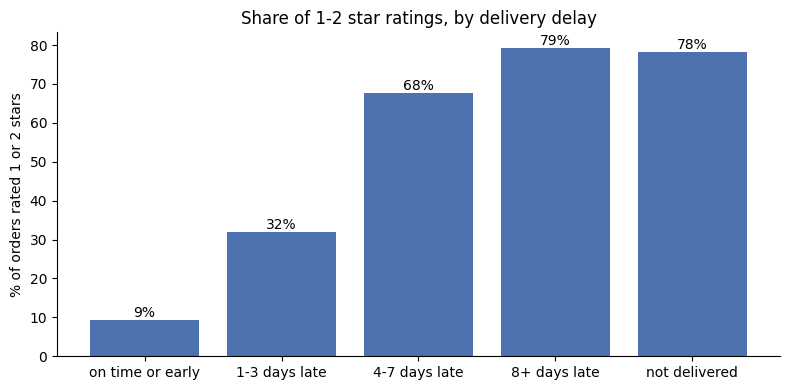

In [64]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
labels = [b.split(". ", 1)[1] for b in lateness["delivery_bucket"]]
bars = ax.bar(labels, lateness["pct_1_or_2_star"], color="#4C72B0")
ax.bar_label(bars, fmt="%.0f%%")
ax.set_ylabel("% of orders rated 1 or 2 stars")
ax.set_title("Share of 1-2 star ratings, by delivery delay")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "rating_by_delivery_delay.png"), dpi=150)
plt.show()

## 4. Pick the reviews for the AI to read

The pool is every clean review with **1 or 2 stars and a written comment**. We tag a random sample of `SAMPLE_SIZE`, not all of them, for two reasons: it stays inside the free tier, and you can still estimate each reason's share for the whole pool with a known margin of error (the same logic you used for return rates in Project 1).

In [65]:
con.sql("""
CREATE OR REPLACE TABLE negative_pool AS
SELECT
  review_id,
  order_id,
  review_score,
  -- join title and comment, and squash line breaks so each review sits on one line in the batch
  TRIM(REGEXP_REPLACE(COALESCE(review_comment_title || '. ', '') || review_comment_message,
                      '\\s+', ' ', 'g')) AS review_text
FROM reviews_clean
WHERE review_score <= 2
  AND review_comment_message IS NOT NULL
  AND LENGTH(TRIM(review_comment_message)) >= 3
ORDER BY review_id
""")

pool = sql("SELECT * FROM negative_pool")
POOL_SIZE = len(pool)
sample = pool.sample(n=min(SAMPLE_SIZE, POOL_SIZE), random_state=RANDOM_SEED).reset_index(drop=True)
print(f"Negative reviews with a comment: {POOL_SIZE:,}")
print(f"Sample for the AI: {len(sample):,}")
sample.head(10)

Negative reviews with a comment: 10,711
Sample for the AI: 1,000


,review_id,order_id,review_score,review_text
0,f634524f5096399d2155d3de739981fd,923c72c5c8bc167cdab01dbd3de020a8,1,"Ainda aguardando. Eu ainda daria mais um tempo para responder, devido ao transtorno da greve dos caminhoneiros, mas ..."
1,a061791c0bec3f4862936b05668466fd,676c554a88771af1264e81fa10e7e760,1,"Decepcionado. A pergunta é, quando vcs irão entregar a minha mercadoria que já foi paga?"
2,082d6bd1e32892e4b4cde2a5cd02ec72,6e0f05728107157ca451dd9047a4eebf,1,Péssimo. Aparelho usado
3,dae5174116d950a23616a58119738eb8,fa42976ec498a7a192277e10b1706a5f,1,"O produto custou R$34 com frete, mas não é bom. É bem ralinho parece água."
4,afd8ebe540ed56e503df915132e81f11,8d4159350057e7ebf61c0083d75c8712,1,Estou esperando o produto.
5,be1334d7ac405616d49b2f421bfea33c,9e99d6f656fcb2d4a76e9455959cf62f,1,Quero meu produto ou estorno!
6,5e7a01af6ac7a1223a1a6cccbd0a33fd,deb46eedbf903626782bcc806f26df87,2,"Meu produto nao foi entregue , produto se quer chegou na minha residencia !"
7,68144df84a53e4f96dcd21173d577b92,ad5ca87a6601228af735af74e4077178,1,Produto incompatível com o note book Acer Aspire F 15 F5-573G74G4
8,a5cfff9868bfbf6aa554f28c6b1196ff,1016b48b6d8c68e73002bdeb36e3deb1,2,Infelizmente demorou um pouco para chegar.
9,18b88e111929bd2167c44214bbf8854c,e6152cd6ca627fc4f0f5deddea24f7c2,1,Nao recebi o produto


## 5. Set up the AI classifier

Three pieces, each one a choice you should be able to explain:
1. **A fixed list of reason codes (the taxonomy).** The model must pick from this list, so results can be counted. The codes mirror the contact reasons a CX team would use.
2. **A prompt with definitions, tie-break rules and examples.** Clear definitions are what make labels consistent, for an AI or for a team of human agents.
3. **A response schema.** The model must reply in a fixed JSON structure, so there is no messy text to clean up.

In [66]:
from enum import Enum
from pydantic import BaseModel
from google import genai
from google.genai import types
from google.colab import userdata

client = genai.Client(api_key=userdata.get("GEMINI_API_KEY"))

class Reason(str, Enum):
    late_delivery = "late_delivery"
    not_received = "not_received"
    missing_items = "missing_items"
    wrong_item = "wrong_item"
    damaged_or_defective = "damaged_or_defective"
    not_as_described = "not_as_described"
    seller_or_support = "seller_or_support"
    other = "other"
    no_clear_reason = "no_clear_reason"

class Confidence(str, Enum):
    high = "high"
    medium = "medium"
    low = "low"

class Label(BaseModel):
    item: int                 # the review's number in the batch
    primary_reason: Reason
    summary_en: str           # what went wrong, in English
    confidence: Confidence

REASON_CODES = [r.value for r in Reason]
print(REASON_CODES)

['late_delivery', 'not_received', 'missing_items', 'wrong_item', 'damaged_or_defective', 'not_as_described', 'seller_or_support', 'other', 'no_clear_reason']


In [67]:
SYSTEM_PROMPT = """
You are a customer-experience analyst at a Brazilian e-commerce marketplace.
You will receive numbered customer reviews written in Brazilian Portuguese.
Every review gave the order 1 or 2 stars.

For each review, choose the ONE main reason the customer is unhappy, using exactly one code:

- late_delivery: the order arrived, but later than promised, or the main complaint is slow delivery.
- not_received: the customer says the order, or the whole order, has not arrived or never arrived.
- missing_items: the order arrived incomplete. Some items or units are missing, or only part of a multi-item order came.
- wrong_item: the customer received a different product, colour, size or model from the one ordered.
- damaged_or_defective: the product arrived broken or damaged, or does not work.
- not_as_described: the product works, but its quality, size, material or features are worse than the listing, or it is fake.
- seller_or_support: the problem is the service, not the product: no reply from the seller or store, a cancellation, a refund or exchange not processed, or an invoice or billing problem.
- other: a clear complaint that fits none of the codes above.
- no_clear_reason: the text does not say what went wrong (for example "terrible" or "do not recommend").

Tie-break rules:
1. If the customer says the product has not arrived, use not_received, even if they also mention a delay.
2. If the order arrived incomplete, use missing_items, even if the missing part might come later.
3. Otherwise, pick the reason that would have to be fixed first to prevent this complaint.

For each review return:
- item: the review number you were given
- primary_reason: one code from the list
- summary_en: what went wrong, in plain English, at most 15 words
- confidence: high, medium or low

Examples:
"Até agora não recebi o produto e já passou do prazo." -> not_received
"Chegou com 10 dias de atraso, mas o produto é bom." -> late_delivery
"Comprei 2 unidades e veio apenas 1." -> missing_items
"A tela veio quebrada." -> damaged_or_defective
"Pedi azul e veio preto." -> wrong_item
"Péssimo." -> no_clear_reason
""".strip()

# Save the prompt so it is visible in the GitHub repo.
with open(os.path.join(OUT_DIR, "prompt.txt"), "w") as f:
    f.write(SYSTEM_PROMPT)
print(len(SYSTEM_PROMPT.split()), "words in the prompt")

349 words in the prompt


**The function that sends one batch.** It numbers the reviews, sends them with the prompt, and maps each answer back to its review ID. It also records token usage, which you need for the cost comparison later.

`temperature=0` makes the model as consistent as possible: the same review should get the same label every time.

In [68]:
import time

def classify_batch(batch):
    """Send one batch of reviews to the model. Returns (labels table, usage dict)."""
    numbered = "\n".join(f"{i}. {text}" for i, text in enumerate(batch["review_text"], start=1))
    started = time.time()
    response = client.models.generate_content(
        model=MODEL,
        contents=numbered,
        config=types.GenerateContentConfig(
            system_instruction=SYSTEM_PROMPT,
            temperature=0,
            response_mime_type="application/json",
            response_schema=list[Label],
        ),
    )
    seconds = time.time() - started

    rows = []
    for label in response.parsed or []:
        if 1 <= label.item <= len(batch):              # ignore any number the model made up
            rows.append({
                "review_id": batch["review_id"].iloc[label.item - 1],
                "primary_reason": label.primary_reason.value,
                "summary_en": label.summary_en,
                "confidence": label.confidence.value,
            })
    labels = pd.DataFrame(rows).drop_duplicates("review_id") if rows else pd.DataFrame(
        columns=["review_id", "primary_reason", "summary_en", "confidence"])

    u = response.usage_metadata
    usage = {
        "reviews_sent": len(batch),
        "labels_returned": len(labels),
        "input_tokens": u.prompt_token_count or 0,
        "output_tokens": (u.candidates_token_count or 0) + (u.thoughts_token_count or 0),
        "seconds": round(seconds, 2),
    }
    return labels, usage

**Test on 5 reviews first.** Read each Portuguese review next to the English summary and the code. If something looks off, fix the definitions in the prompt now, before spending the full run. Interview line: *"I tested on a small batch and tightened the prompt before running at scale."*

In [69]:
test_batch = sample.head(5)
test_labels, test_usage = classify_batch(test_batch)
display(test_batch[["review_id", "review_text"]].merge(test_labels, on="review_id"))
print(test_usage)

,review_id,review_text,primary_reason,summary_en,confidence
0,f634524f5096399d2155d3de739981fd,"Ainda aguardando. Eu ainda daria mais um tempo para responder, devido ao transtorno da greve dos caminhoneiros, mas ...",not_received,Customer has not received the order despite repeated inquiries from the store.,high
1,a061791c0bec3f4862936b05668466fd,"Decepcionado. A pergunta é, quando vcs irão entregar a minha mercadoria que já foi paga?",not_received,The paid order has not been delivered yet.,high
2,082d6bd1e32892e4b4cde2a5cd02ec72,Péssimo. Aparelho usado,not_as_described,The device received was used instead of new.,high
3,dae5174116d950a23616a58119738eb8,"O produto custou R$34 com frete, mas não é bom. É bem ralinho parece água.",not_as_described,The product quality is poor and does not match expectations.,high
4,afd8ebe540ed56e503df915132e81f11,Estou esperando o produto.,not_received,The customer is still waiting for the product to arrive.,high


{'reviews_sent': 5, 'labels_returned': 5, 'input_tokens': 665, 'output_tokens': 270, 'seconds': 3.61}


## 6. Run the full sample

This takes roughly 5 to 10 minutes. Results are saved after every batch, so if Colab disconnects or you hit a rate limit, **just run the cell again**: it skips reviews that already have a label and carries on. Run it again too if the summary at the end says some reviews are still missing a label.

In [70]:
LABELS_FILE = os.path.join(DATA_OUT, "ai_labels.csv")
USAGE_FILE = os.path.join(DATA_OUT, "api_usage.csv")

def call_with_retry(batch, attempts=5):
    for attempt in range(1, attempts + 1):
        try:
            return classify_batch(batch)
        except Exception as e:
            code = getattr(e, "code", None)
            if code in (429, 500, 503) and attempt < attempts:
                wait = 30 * attempt
                print(f"  API said {code}; waiting {wait}s and retrying")
                time.sleep(wait)
            else:
                raise

done = pd.read_csv(LABELS_FILE) if os.path.exists(LABELS_FILE) else pd.DataFrame(columns=["review_id"])
todo = sample[~sample["review_id"].isin(done["review_id"])]
print(f"Already labelled: {len(done):,}. To do: {len(todo):,}.")

for start in range(0, len(todo), BATCH_SIZE):
    batch = todo.iloc[start:start + BATCH_SIZE]
    labels, usage = call_with_retry(batch)
    labels.to_csv(LABELS_FILE, mode="a", header=not os.path.exists(LABELS_FILE), index=False)
    pd.DataFrame([usage]).to_csv(USAGE_FILE, mode="a", header=not os.path.exists(USAGE_FILE), index=False)
    print(f"  batch {start // BATCH_SIZE + 1}: {usage['labels_returned']}/{usage['reviews_sent']} labelled")
    time.sleep(PAUSE_SECONDS)

labels_all = pd.read_csv(LABELS_FILE).drop_duplicates("review_id")
missing = len(sample) - sample["review_id"].isin(labels_all["review_id"]).sum()
print(f"Done. Labelled {len(labels_all):,} of {len(sample):,}. Still missing: {missing}.")

Already labelled: 1,000. To do: 0.
Done. Labelled 1,000 of 1,000. Still missing: 0.


## 7. Results: why are customers unhappy?

Each reason's share of the sample, its **margin of error** (95% confidence), and an estimate for the full pool of negative reviews. Reasons whose ranges overlap are not meaningfully different, so do not over-read small gaps.

In [71]:
ai = sample.merge(pd.read_csv(LABELS_FILE).drop_duplicates("review_id"), on="review_id")
con.register("ai_labels", ai)

reasons = sql(f"""
WITH counts AS (
  SELECT primary_reason, COUNT(*) AS n
  FROM ai_labels
  GROUP BY primary_reason
),
total AS (SELECT SUM(n) AS total FROM counts)
SELECT
  c.primary_reason,
  c.n                                                             AS reviews_in_sample,
  ROUND(100.0 * c.n / t.total, 1)                                 AS pct_of_sample,
  ROUND(100 * 1.96 * SQRT((c.n / t.total) * (1 - c.n / t.total) / t.total), 1) AS margin_pts,
  ROUND(c.n / t.total * {POOL_SIZE})                              AS est_reviews_in_full_pool
FROM counts c CROSS JOIN total t
ORDER BY c.n DESC
""")
reasons

,primary_reason,reviews_in_sample,pct_of_sample,margin_pts,est_reviews_in_full_pool
0,not_received,283,28.3,2.8,3031.0
1,missing_items,145,14.5,2.2,1553.0
2,not_as_described,131,13.1,2.1,1403.0
3,seller_or_support,106,10.6,1.9,1135.0
4,wrong_item,102,10.2,1.9,1093.0
5,damaged_or_defective,90,9.0,1.8,964.0
6,late_delivery,84,8.4,1.7,900.0
7,no_clear_reason,41,4.1,1.2,439.0
8,other,18,1.8,0.8,193.0


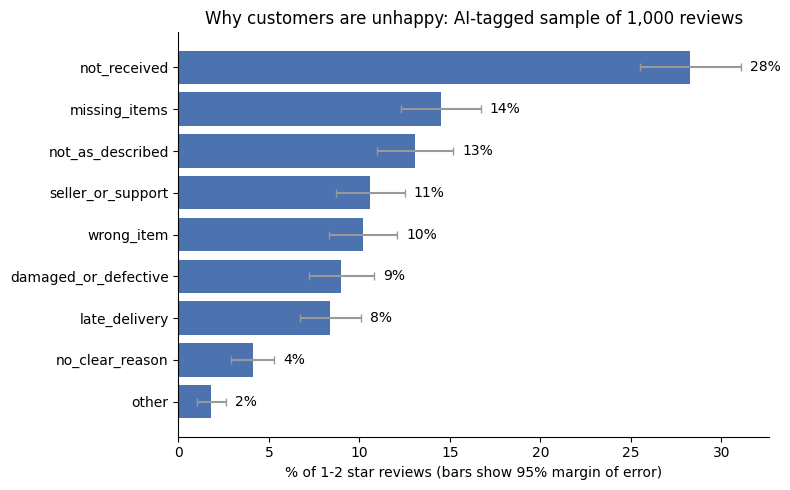

In [72]:
plot = reasons.sort_values("pct_of_sample")
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(plot["primary_reason"], plot["pct_of_sample"], xerr=plot["margin_pts"],
        color="#4C72B0", ecolor="#999999", capsize=3)
for y, (pct, moe) in enumerate(zip(plot["pct_of_sample"], plot["margin_pts"])):
    ax.text(pct + moe + 0.5, y, f"{pct:.0f}%", va="center")
ax.set_xlabel("% of 1-2 star reviews (bars show 95% margin of error)")
ax.set_title(f"Why customers are unhappy: AI-tagged sample of {len(ai):,} reviews")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "complaint_reasons.png"), dpi=150)
plt.show()

**Spot-check: three random examples per reason.** Read these. They become the quotes and examples in your README, and they are the fastest way to see whether a code is being misused.

In [73]:
pd.set_option("display.max_colwidth", 120)
(ai.sample(frac=1, random_state=RANDOM_SEED)      # shuffle
   .groupby("primary_reason").head(3)                # then take the first 3 of each reason
   .sort_values("primary_reason")
   [["primary_reason", "review_text", "summary_en", "confidence"]])

,primary_reason,review_text,summary_en,confidence
521,damaged_or_defective,PESSIMA. Esta com defeito danificou todas as imagem salvas e eu perdi 182 fotos.,Defective product caused data loss.,high
737,damaged_or_defective,Produto veio com defeito. Antes de recomendar a loja preciso ver se a loja irá trocar o produto que veio com defeito...,"Product arrived defective, waiting for exchange.",high
136,damaged_or_defective,"Recebi o produto cheio de defeitos. Já solicitei devolução do dinheiro, estou aguardando retorno",Product arrived defective and return is pending.,high
312,late_delivery,O prazo de entrega e muito longo e quando chega na data de previsão de entrega o produto não foi entregue.,Delivery deadline is long and product was not delivered on time.,high
542,late_delivery,Gostaria de saber o que aconteceu o prazo que me deram foi até dia 19 e nada ainda.,Delivery deadline passed and product has not arrived.,high
879,late_delivery,Como a entrega esta muito atrasada não vou fazer nenhuma avaliação,Delivery is significantly delayed.,high
761,missing_items,"Recebi produtos diferentes do anunciado e pior de 02 und compradas recebi somente 01 und. Não gostei, pedi a devoluç...",Received wrong items and only one unit instead of two.,high
678,missing_items,Nós compramos 5 pufs mas só foram entregues 4,Only 4 out of 5 poufs were delivered.,high
626,missing_items,Foi a pior compra pela internet que fiz até hoje. O pedido foi entregue pela metade. A nota fiscal saiu errada. Esto...,Order arrived incomplete and invoice is incorrect.,high
959,no_clear_reason,Não gostei muito Rui,General dissatisfaction without specific details.,high


## 8. Check 1: does the AI agree with a human? (you)

This is the step most AI portfolio projects skip, and the one that makes yours credible. You label 100 reviews yourself **without seeing the AI's answer**, then we measure agreement.

**Steps**
1. Run the next cell. It saves `human_label_sheet.csv` (100 random reviews, no AI labels).
2. Open Google Sheets, then **File > Import > Upload** that file.
3. In column D, add an English translation: put `=GOOGLETRANSLATE(B2,"pt","en")` in D2 and drag it down. (Google Translate is independent of Gemini, so the AI's view does not leak into yours.)
4. In column C (`my_label`), type one reason code per row from the list printed below. Tip: **Data > Data validation > Dropdown** with the nine codes stops typos.
5. **File > Download > CSV**, rename it `human_labels.csv`, and upload it to the outputs folder (the path printed below).
6. Run the cell after that.

In [74]:
HUMAN_SHEET = os.path.join(DATA_OUT, "human_label_sheet.csv")
HUMAN_LABELS = os.path.join(DATA_OUT, "human_labels.csv")

if not os.path.exists(HUMAN_SHEET):
    to_label = ai.sample(n=min(100, len(ai)), random_state=RANDOM_SEED)[["review_id", "review_text"]].copy()
    to_label["my_label"] = ""
    to_label.to_csv(HUMAN_SHEET, index=False)

print("Sheet to label:", HUMAN_SHEET)
print("Upload your finished file as:", HUMAN_LABELS)
print("Codes:", ", ".join(REASON_CODES))

Sheet to label: /content/drive/MyDrive/ai-complaint-triage/data/human_label_sheet.csv
Upload your finished file as: /content/drive/MyDrive/ai-complaint-triage/data/human_labels.csv
Codes: late_delivery, not_received, missing_items, wrong_item, damaged_or_defective, not_as_described, seller_or_support, other, no_clear_reason


In [75]:
from sklearn.metrics import accuracy_score, cohen_kappa_score

if not os.path.exists(HUMAN_LABELS):
    print("human_labels.csv not found yet. Finish the labelling steps above, then run this cell again.")
else:
    human = pd.read_csv(HUMAN_LABELS)[["review_id", "my_label"]].dropna()
    human["my_label"] = human["my_label"].str.strip()
    bad = human[~human["my_label"].isin(REASON_CODES)]
    if len(bad):
        print(f"Skipping {len(bad)} rows whose label is not a valid code (typos?): {sorted(bad['my_label'].unique())}")
        print("Fix them in your sheet and re-upload for a complete score.\n")
    human = human[human["my_label"].isin(REASON_CODES)]
    check = human.merge(ai[["review_id", "review_text", "primary_reason", "summary_en"]], on="review_id")
    accuracy = accuracy_score(check["my_label"], check["primary_reason"])
    kappa = cohen_kappa_score(check["my_label"], check["primary_reason"])
    print(f"Reviews compared: {len(check)}")
    print(f"Agreement with your labels: {accuracy:.0%}")
    print(f"Cohen's kappa: {kappa:.2f}   (above 0.6 is good, above 0.8 is very strong)")

    display(pd.crosstab(check["my_label"], check["primary_reason"],
                        rownames=["you"], colnames=["AI"]))
    print("\nDisagreements (read these: do they show a weak definition in the prompt?)")
    display(check[check["my_label"] != check["primary_reason"]][
        ["review_text", "my_label", "primary_reason", "summary_en"]])

Reviews compared: 100
Agreement with your labels: 78%
Cohen's kappa: 0.74   (above 0.6 is good, above 0.8 is very strong)


AI,damaged_or_defective,late_delivery,missing_items,no_clear_reason,not_as_described,not_received,other,seller_or_support,wrong_item
you,,,,,,,,,
damaged_or_defective,10,0,0,0,0,0,0,0,0
late_delivery,1,7,0,0,1,1,0,0,0
missing_items,0,0,16,0,0,0,0,0,0
not_as_described,0,0,0,0,5,0,0,0,2
not_received,0,0,1,0,0,27,0,0,1
other,0,0,0,1,5,0,1,5,0
seller_or_support,0,0,0,0,0,0,1,5,0
wrong_item,1,0,1,0,1,0,0,0,7



Disagreements (read these: do they show a weak definition in the prompt?)


,review_text,my_label,primary_reason,summary_en
6,Foi a pior compra pela internet que fiz até hoje. O pedido foi entregue pela metade. A nota fiscal saiu errada. Esto...,not_received,missing_items,Order arrived incomplete and invoice is incorrect.
10,"E não comprarei mais, cobra-se um valor do cartão de crédito e a NFiscal vem com outro valor, como preciso fechar a ...",other,seller_or_support,Discrepancy between credit card charge and invoice value.
11,"toalhas muito finas, qualidade inferior",other,not_as_described,Towels are too thin and of inferior quality.
12,Quando colocar toalha felpuda que seja e não foi.,other,not_as_described,Towel was not the plush material as expected.
14,Loja péssima mandou buscar o tapete na china,seller_or_support,other,Customer is complaining about the store's logistics/location.
18,"Recebi produtos diferentes do anunciado e pior de 02 und compradas recebi somente 01 und. Não gostei, pedi a devoluç...",wrong_item,missing_items,Received wrong items and only one unit instead of two.
19,Minha impressora não tá reconhecendo o cartucho colorido que comprei. Comprei um original para não ter nenhum tipo d...,wrong_item,damaged_or_defective,Printer does not recognize the new original cartridge.
28,"Foto não condiz . A cor da foto é uma, e o produto é completamente diferente, muito mais claro.",wrong_item,not_as_described,The product color is completely different from the photo shown online.
31,"O produto demorou cerca de dois meses para chegar. Além disso, o produto não contém as medidas divulgadas no anúncio...",late_delivery,not_as_described,Product arrived late and does not match advertised dimensions.
32,nada,other,no_clear_reason,No specific reason provided in the review.


**If agreement is below about 80%:** look at the disagreements. Usually one or two codes are blurry (for example `damaged_or_defective` versus `not_as_described`). Sharpen those definitions in the prompt, delete `ai_labels.csv`, and rerun from section 6. Keep a note of the before and after numbers: *"accuracy went from 74% to 88% after I fixed two definitions"* is a strong interview story.

Kappa matters because it corrects for agreement by chance. If 40% of reviews are late deliveries, a model that always says "late" would agree 40% of the time while being useless; kappa would be near zero.

## 9. Check 2: does the AI agree with the operational data?

The AI only read the text. The orders table independently records whether each order actually arrived late. If the AI is right, reviews it tagged as delivery problems should be far more likely to be late in the data than reviews it tagged as something else.

Caveat: "late" here means later than the date the customer was promised. A customer can complain about slowness even when the order arrived inside a long promise window, so 100% is not expected.

In [76]:
delivery_check = sql("""
SELECT
  a.primary_reason,
  COUNT(*)                                                                AS reviews,
  ROUND(100.0 * AVG(CASE WHEN f.days_late > 0 THEN 1 ELSE 0 END), 1)      AS pct_delivered_late,
  ROUND(100.0 * AVG(CASE WHEN f.not_delivered THEN 1 ELSE 0 END), 1)      AS pct_never_delivered,
  ROUND(100.0 * AVG(CASE WHEN f.days_late > 0 OR f.not_delivered THEN 1 ELSE 0 END), 1) AS pct_late_or_never
FROM ai_labels a
JOIN order_facts f ON a.order_id = f.order_id
GROUP BY a.primary_reason
ORDER BY pct_late_or_never DESC
""")
delivery_check

,primary_reason,reviews,pct_delivered_late,pct_never_delivered,pct_late_or_never
0,not_received,283,51.9,29.3,81.3
1,seller_or_support,106,16.0,52.8,68.9
2,late_delivery,84,50.0,14.3,64.3
3,no_clear_reason,41,43.9,19.5,63.4
4,other,18,16.7,5.6,22.2
5,wrong_item,102,2.0,2.0,3.9
6,not_as_described,131,3.8,0.0,3.8
7,missing_items,145,3.4,0.0,3.4
8,damaged_or_defective,90,1.1,0.0,1.1


## 10. Impact: what should operations fix first?

Volume alone is not enough. This adds the **value of the orders** behind each complaint reason and estimates the total for the full pool.

In [77]:
impact = sql(f"""
SELECT
  a.primary_reason,
  COUNT(*)                                    AS reviews_in_sample,
  ROUND(AVG(f.order_value_brl), 0)            AS avg_order_value_brl,
  ROUND(SUM(f.order_value_brl), 0)            AS order_value_in_sample_brl,
  ROUND(SUM(f.order_value_brl) * {POOL_SIZE} / (SELECT COUNT(*) FROM ai_labels), 0)
                                              AS est_order_value_full_pool_brl
FROM ai_labels a
JOIN order_facts f ON a.order_id = f.order_id
GROUP BY a.primary_reason
ORDER BY est_order_value_full_pool_brl DESC
""")
impact

,primary_reason,reviews_in_sample,avg_order_value_brl,order_value_in_sample_brl,est_order_value_full_pool_brl
0,not_received,283,187.0,50173.0,537398.0
1,missing_items,145,249.0,36097.0,386631.0
2,not_as_described,131,141.0,18411.0,197202.0
3,wrong_item,102,182.0,18356.0,196609.0
4,seller_or_support,106,219.0,17502.0,187459.0
5,damaged_or_defective,90,189.0,16982.0,181892.0
6,late_delivery,84,181.0,14871.0,159281.0
7,no_clear_reason,41,199.0,7961.0,85267.0
8,other,18,223.0,3787.0,40558.0


**Root-cause probe: are missing items a split-shipment problem?** Orders with items from more than one seller ship in separate parcels, so the customer may receive one box and think the rest is missing. If `missing_items` complaints are much more common on multi-seller orders, the fix is communication at checkout and tracking, not the warehouse.

In [78]:
sql("""
SELECT
  CASE WHEN f.n_sellers > 1 THEN 'multi-seller order' ELSE 'single-seller order' END AS order_type,
  COUNT(*)                                                                   AS negative_reviews,
  ROUND(100.0 * AVG(CASE WHEN a.primary_reason = 'missing_items' THEN 1 ELSE 0 END), 1) AS pct_missing_items
FROM ai_labels a
JOIN order_facts f ON a.order_id = f.order_id
GROUP BY 1
""")

,order_type,negative_reviews,pct_missing_items
0,single-seller order,961,12.2
1,multi-seller order,39,71.8


**Product problems by category.** Where do damaged, defective or not-as-described complaints concentrate? These point at seller quality or packaging, rather than logistics.

In [79]:
sql("""
SELECT
  f.category,
  COUNT(*)                                                                    AS negative_reviews,
  SUM(CASE WHEN a.primary_reason IN ('damaged_or_defective', 'not_as_described') THEN 1 ELSE 0 END) AS product_problems,
  ROUND(100.0 * AVG(CASE WHEN a.primary_reason IN ('damaged_or_defective', 'not_as_described') THEN 1 ELSE 0 END), 1)
                                                                              AS pct_product_problems
FROM ai_labels a
JOIN order_facts f ON a.order_id = f.order_id
GROUP BY f.category
HAVING COUNT(*) >= 20
ORDER BY product_problems DESC
LIMIT 8
""")

,category,negative_reviews,product_problems,pct_product_problems
0,computers_accessories,79,26.0,32.9
1,bed_bath_table,110,25.0,22.7
2,furniture_decor,70,19.0,27.1
3,watches_gifts,57,16.0,28.1
4,cool_stuff,39,13.0,33.3
5,health_beauty,63,11.0,17.5
6,auto,32,11.0,34.4
7,telephony,44,11.0,25.0


## 11. What did the AI cost, and what would manual tagging cost?

The run was free on the free tier. To make the business case, we also price it at the paid list price, and compare with a CX agent tagging the same reviews by hand. `MANUAL_SECONDS_PER_REVIEW` is an assumption; say so in your README.

In [80]:
usage = pd.read_csv(USAGE_FILE)
n_labelled = len(ai)
input_tokens = usage["input_tokens"].sum()
output_tokens = usage["output_tokens"].sum()
cost_usd = input_tokens / 1e6 * PRICE_INPUT_PER_M + output_tokens / 1e6 * PRICE_OUTPUT_PER_M
api_minutes = usage["seconds"].sum() / 60
manual_hours = n_labelled * MANUAL_SECONDS_PER_REVIEW / 3600

cost_table = pd.DataFrame({
    "metric": ["reviews labelled", "API calls", "input tokens", "output tokens",
               "cost at paid list price (USD)", "cost per 1,000 reviews (USD)",
               "model processing time (minutes)", f"manual tagging at {MANUAL_SECONDS_PER_REVIEW}s each (hours)"],
    "value": [f"{n_labelled:,}", f"{len(usage):,}", f"{input_tokens:,}", f"{output_tokens:,}",
              f"${cost_usd:.3f}", f"${cost_usd / n_labelled * 1000:.3f}",
              f"{api_minutes:.1f}", f"{manual_hours:.1f}"],
})
cost_table

,metric,value
0,reviews labelled,"1,000"
1,API calls,40
2,input tokens,"51,107"
3,output tokens,"47,520"
4,cost at paid list price (USD),$0.084
5,"cost per 1,000 reviews (USD)",$0.084
6,model processing time (minutes),3.7
7,manual tagging at 30s each (hours),8.3


## 12. Wrap up

The next cell prints every headline number in one block. **Copy the whole output and paste it back into your chat with Claude** to draft the README's findings and recommendations.

Then download from your outputs folder: `images/` (2 charts), `data/ai_labels.csv`, `data/human_labels.csv` and `prompt.txt`. Also download this notebook (**File > Download > .ipynb**) with its outputs showing, since reviewers on GitHub will read it.

In [81]:
def show(title, df):
    print(f"\n=== {title} ===")
    print(df.to_string(index=False))

print(f"Model: {MODEL} | sample: {len(ai):,} of {POOL_SIZE:,} negative reviews with comments | seed {RANDOM_SEED}")
show("Review score mix", score_mix)
show("Rating by delivery delay", lateness)
show("Complaint reasons (AI)", reasons)
show("Delivery cross-check", delivery_check)
show("Order value by reason", impact)
show("AI cost", cost_table)
if os.path.exists(HUMAN_LABELS):
    print(f"\nHuman agreement: {accuracy:.0%}, kappa {kappa:.2f}, n={len(check)}")
else:
    print("\nHuman agreement: not done yet")

Model: gemini-3.1-flash-lite | sample: 1,000 of 10,711 negative reviews with comments | seed 42

=== Review score mix ===
 review_score  reviews  pct
            1    11247 11.5
            2     3103  3.2
            3     8073  8.2
            4    18951 19.3
            5    56721 57.8

=== Rating by delivery delay ===
    delivery_bucket  orders  pct_of_orders  avg_score  pct_1_or_2_star
1. on time or early   88953           90.7       4.29              9.2
   2. 1-3 days late    1840            1.9       3.30             32.0
   3. 4-7 days late    1739            1.8       2.10             67.6
    4. 8+ days late    2768            2.8       1.69             79.3
   5. not delivered    2795            2.8       1.74             78.3

=== Complaint reasons (AI) ===
      primary_reason  reviews_in_sample  pct_of_sample  margin_pts  est_reviews_in_full_pool
        not_received                283           28.3         2.8                    3031.0
       missing_items            